In [1]:
using LinearAlgebra
using Plots
struct System
    num_p::Int
    m::Vector{Float64}     
    x::Matrix{Float64}     
    v::Matrix{Float64}    
    G::Float64             
end


In [2]:
function center_of_mass_correction(sys::System)
    M = sum(sys.m)
    x_cm = sum(sys.x .* sys.m, dims=1) / M
    v_cm = sum(sys.v .* sys.m, dims=1) / M
    sys.x .-= x_cm
    sys.v .-= v_cm
end

center_of_mass_correction (generic function with 1 method)

In [3]:
using LinearAlgebra


names = ["Sun", "Mercury", "Venus", "Earth", "Mars", "Jupiter", "Saturn", "Uranus", "Neptune"]

masses =[   1.0,                        
    1.660e-7,                   
    2.447e-6,                   
    3.003e-6,                   
    3.213e-7,                   
    9.543e-4,                   
    2.858e-4,                  
    4.366e-5,                   
    5.129e-5                    
]

positions = [
    [0.0, 0.0, 0.0],
    [-0.389724, -0.130651, 0.023594],
    [-0.718441, 0.032897, 0.041066],
    [-0.184276, 0.967219, -0.000042],
    [1.3826, -0.1357, -0.0345],
    [-3.5024, -2.7699, 0.0819],
    [5.744, -7.963, -0.101],
    [17.906, 9.914, -0.179],
    [28.92, -8.025, -0.524]
]

velocities = [
    [0.0, 0.0, 0.0],
    [0.004434, -0.024953, -0.002545],
    [-0.001143, -0.020212, -0.000351],
    [-0.017202, -0.003279, 0.0],
    [0.00118, 0.0150, 0.00029],
    [0.00447, -0.00607, -0.0001],
    [0.0047, 0.0032, -0.0002],
    [-0.0026, 0.0036, 0.00005],
    [0.0016, 0.0031, -0.0001]
]

m = masses
x = hcat(positions...)'
v = hcat(velocities...)'

num_p =9

G=0.00029591220828559104
sys=System(num_p,m,x,v,G)
center_of_mass_correction(sys)

9×3 Matrix{Float64}:
 -5.51679e-6   4.61431e-6   1.56514e-7
  0.00442848  -0.0249484   -0.00254484
 -0.00114852  -0.0202074   -0.000350843
 -0.0172075   -0.00327439   1.56514e-7
  0.00117448   0.0150046    0.000290157
  0.00446448  -0.00606539  -9.98435e-5
  0.00469448   0.00320461  -0.000199843
 -0.00260552   0.00360461   5.01565e-5
  0.00159448   0.00310461  -9.98435e-5

In [21]:
function acceleration(a::Matrix{Float64}, sys)
    fill!(a, 0.0)
    
    x = sys.x  
    m = sys.m  
    G = sys.G
    N = size(x, 1)
    
    @assert size(a) == (N, 3)

    r_ij = zeros(N, N, 3)
    for i in 1:N, j in 1:N
        r_ij[i, j, :] = x[j, :] - x[i, :]
    end

    r_norm = [norm(r_ij[i, j, :]) for i in 1:N, j in 1:N]

    inv_r_cubed = zeros(N, N)
    for i in 1:N, j in 1:N
        if i != j && r_norm[i, j] > 0
            inv_r_cubed[i, j] = 1 / r_norm[i, j]^3
        end
    end

    for i in 1:N
        ac = zeros(3)
        for j in 1:N
            ac .+= r_ij[i, j, :] .* inv_r_cubed[i, j] * m[j]
        end
        a[i, :] .= G .* ac
    end
end


acceleration (generic function with 1 method)

In [33]:
function runge_kutta(sys, dt)
    x = copy(sys.x)
    v = copy(sys.v)
    N = sys.num_p

    # K1
    a1  = zeros(N, 3)
    acceleration(a1, sys)
    k1v = dt .* a1
    k1x = dt .* v

    # K2
    x2 = x .+ 0.5 .* k1x
    v2 = v .+ 0.5 .* k1v
    a2 = zeros(N, 3)
    temp_sys2 = System(N, sys.m, x2, v2, sys.G)
    acceleration(a2, temp_sys2)
    k2v = dt .* a2
    k2x = dt .* v2

    # K3
    x3 = x .+ 0.5 .* k2x
    v3 = v .+ 0.5 .* k2v
    a3 = zeros(N, 3)
    temp_sys3 = System(N, sys.m, x3, v3, sys.G)
    acceleration(a3, temp_sys3)
    k3v = dt .* a3
    k3x = dt .* v3

    # K4
    x4 = x .+ k3x
    v4 = v .+ k3v
    a4 = zeros(N, 3)
    temp_sys4 = System(N, sys.m, x4, v4, sys.G)
    acceleration(a4, temp_sys4)
    k4v = dt .* a4
    k4x = dt .* v4

    # Final Step
    for i in 1:N
        sys.v[i, :] .= sys.v[i, :] .+ (k1v[i, :] + 2*k2v[i, :] + 2*k3v[i, :] + k4v[i, :]) / 6
        sys.x[i, :] .= sys.x[i, :] .+ (k1x[i, :] + 2*k2x[i, :] + 2*k3x[i, :] + k4x[i, :]) / 6
    end
end


runge_kutta (generic function with 2 methods)

In [27]:
function leapfrog(a::Matrix{Float64}, sys::System, dt::Float64)
    
    acceleration(a, sys)
    sys.v .+= a .* (0.5 * dt)

    sys.x .+= sys.v .* dt

   
    acceleration(a, sys)
    sys.v .+= a .* (0.5 * dt)

    return nothing
end


leapfrog (generic function with 1 method)

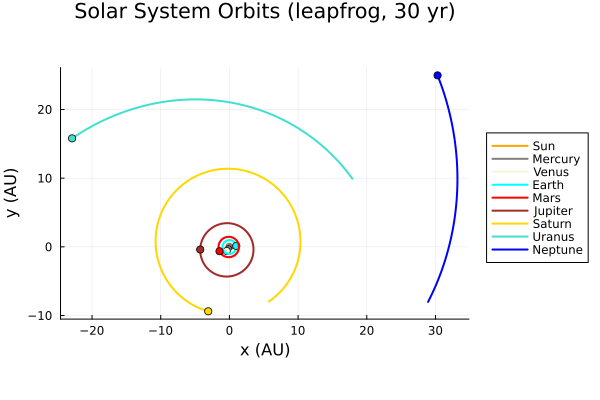

In [29]:
using Plots


sys = System(length(m), m, x, v, G)
center_of_mass_correction(sys)
function simulate(sys::System, dt::Float64, steps::Int)
    N    = length(sys.m)
    traj = [zeros(steps+1,3) for _ in 1:N]

    
    for i in 1:N
        traj[i][1, :] = sys.x[i, :]
    end
     a = zeros(N,3)
    for k in 1:steps
        leapfrog(a,sys, dt)
        for i in 1:N
            traj[i][k+1, :] = sys.x[i, :]
        end
    end
      return traj
end 



dt    = 1.0                       
steps = Int(365*30/dt)           
trajectories = simulate(sys, dt, steps)


plt = plot(
  aspect_ratio = :equal,
  xlabel = "x (AU)", ylabel = "y (AU)",
  title  = "Solar System Orbits (leapfrog, 30 yr)",
  legend = :outerright
)

colors = [:orange, :gray, :beige, :cyan, :red, :brown, :gold, :turquoise, :blue]
names  = ["Sun","Mercury","Venus","Earth","Mars","Jupiter","Saturn","Uranus","Neptune"]

for i in 1:9
  xi = trajectories[i][:,1]; yi = trajectories[i][:,2]
  plot!(plt, xi, yi, color=colors[i], lw=2, label=names[i])
  scatter!(plt, [xi[end]], [yi[end]], color=colors[i], ms=4, label="")
end

display(plt)


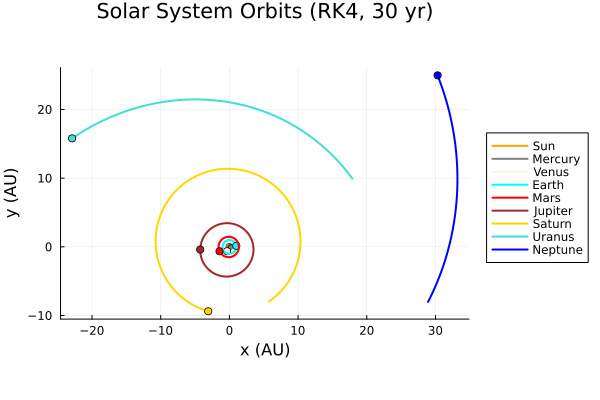

In [44]:
using Plots


sys = System(length(m), m, x, v, G)
center_of_mass_correction(sys)
function simulate(sys::System, dt::Float64, steps::Int)
    N    = length(sys.m)
    traj = [zeros(steps+1,3) for _ in 1:N]

  
    for i in 1:N
        traj[i][1, :] = sys.x[i, :]
    end
     a = zeros(N,3)
    for k in 1:steps
        runge_kutta(sys, dt)
        for i in 1:N
            traj[i][k+1, :] = sys.x[i, :]
        end
    end
      return traj
end 



dt    = 1.0                       
steps = Int(365*30/dt)            
trajectories = simulate(sys, dt, steps)


plt = plot(
  aspect_ratio = :equal,
  xlabel = "x (AU)", ylabel = "y (AU)",
  title  = "Solar System Orbits (RK4, 30 yr)",
  legend = :outerright
)

colors = [:orange, :gray, :beige, :cyan, :red, :brown, :gold, :turquoise, :blue]
names  = ["Sun","Mercury","Venus","Earth","Mars","Jupiter","Saturn","Uranus","Neptune"]

for i in 1:9
  xi = trajectories[i][:,1]; yi = trajectories[i][:,2]
  plot!(plt, xi, yi, color=colors[i], lw=2, label=names[i])
  scatter!(plt, [xi[end]], [yi[end]], color=colors[i], ms=4, label="")
end

display(plt)


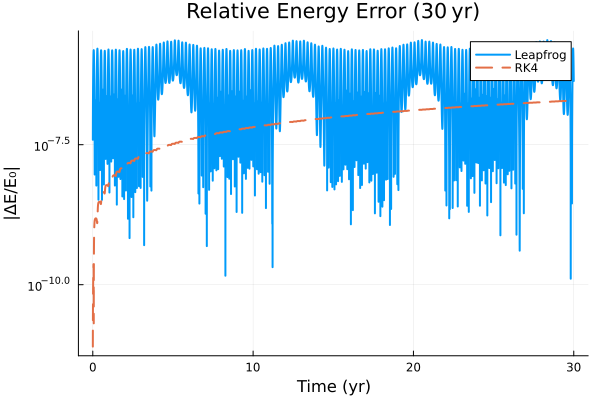

In [30]:
using LinearAlgebra, Plots


function total_energy(sys)
    E = 0.0
    x, v, m, G = sys.x, sys.v, sys.m, sys.G
    N = length(m)
    @inbounds for i in 1:N
        E += 0.5 * m[i] * dot(v[i,:], v[i,:])

        for j in i+1:N
            r = norm(x[i,:] .- x[j,:])
            E -= G * m[i] * m[j] / r
        end
    end
    return E
end


function energy_error(sys0, integrator, dt, steps)
    sys = deepcopy(sys0)                               
    a   = zeros(length(sys.m), 3)                      
    E0  = total_energy(sys)
    errs = zeros(steps+1)
    errs[1] = 0.0

    for k in 1:steps
        if integrator == :leapfrog
            leapfrog(a, sys, dt)                      
        else
            runge_kutta(sys, dt)                       
        end
        errs[k+1] = abs((total_energy(sys) - E0) / E0)
    end

    return errs
end


dt    = 1.0
years = 30
steps = Int(365 * years / dt)


err_lf = energy_error(sys, :leapfrog,    dt, steps)
err_rk = energy_error(sys, :runge_kutta, dt, steps)


time = (0:steps) .* dt ./ 365
t    = time[2:end]
e1   = err_lf[2:end]
e2   = err_rk[2:end]


using Plots
plot(t, e1;
     yscale = :log10,
     lw     = 2,
     label  = "Leapfrog",
     xlabel = "Time (yr)",
     ylabel = "|ΔE/E₀|",
     title  = "Relative Energy Error (30 yr)")
plot!(t, e2;
      lw    = 2,
      ls    = :dash,
      label = "RK4")
